# Fine-Tuning & Evaluation: Phi-3.5-mini-Instruct
## Banking Customer Query Intent Classification (Banking77 Benchmark - 77 Intents)
### Unified Benchmark: 10,003 Train / 1,000 Validation / 2,080 Remaining Test Queries
### Fault-Tolerant, Auto-Resumable Pipeline with Unsloth & QLoRA

- **Target Architecture:** `unsloth/Phi-3.5-mini-instruct`
- **Quantization & PEFT Stack:** 4-bit NormalFloat QLoRA via **Unsloth (FastLanguageModel)**
- **Dataset:** Banking77 (`PolyAI/banking77`):
  - **Train Instances:** **10,003** customer queries
  - **Validation Instances:** **1,000** customer queries (randomly sampled from test set with fixed seed=42)
  - **Remaining Test Instances:** **2,080** customer queries (shared identically across all 6 notebooks)
  - **Target Task:** Fine-grained multi-class intent classification across 77 banking customer service categories
- **Three Experimental Tracks:**
  1. **Experiment 1 — Baseline Prompting:** Zero-shot direct task formulation
  2. **Experiment 2 — Few-Shot Prompting:** In-context learning with 3 representative exemplars
  3. **Experiment 3 — Feature-Aware Prompting:** Structured domain entity & action indicator extraction
- **Built-in Fault Tolerance & Automatic Resumption:**
  - **Evaluation Caching:** Finished prompt evaluations are cached to disk and skipped upon restart.
  - **Batch-Level Resume:** If stopped mid-evaluation, resumes from the last processed instance.
  - **Training Checkpoints:** Periodic checkpoints (`save_steps=250`). Resumes automatically via `resume_from_checkpoint`.
  - **Completed Training Bypass:** If fine-tuning is already complete, skips training and reloads the saved adapter.
  - **Persistent Drive Sync:** Automatically saves checkpoints to Google Drive (in Colab) or local disk.


## 1. System Environment & GPU Diagnostics
Checks available GPU hardware (Nvidia T4, P100, L4, or A100), VRAM allocation, and CUDA capability.


In [1]:
import torch
import os
import sys

print("=== SYSTEM & HARDWARE DIAGNOSTICS ===")
print(f"Python Version: {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    total_vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    cuda_cap = torch.cuda.get_device_capability(0)
    print(f"GPU Device: {device_name}")
    print(f"Total VRAM: {total_vram_gb:.2f} GB")
    print(f"CUDA Capability: {cuda_cap}")
    print(f"bfloat16 Supported: {torch.cuda.is_bf16_supported()}")
else:
    print("[WARNING] No GPU detected! Please navigate to Runtime -> Change runtime type -> Select T4 GPU.")


=== SYSTEM & HARDWARE DIAGNOSTICS ===
Python Version: 3.13.15
PyTorch Version: 2.11.0+cu130
CUDA Available: True
GPU Device: Tesla T4
Total VRAM: 14.56 GB
CUDA Capability: (7, 5)
bfloat16 Supported: True


## 2. Accelerated Unsloth & Dependency Installation
Installs `unsloth` along with pre-compiled PEFT, acceleration, evaluation, and visualization tools (~1-2 minutes, zero source compilation).


In [2]:
# Install Unsloth and required PEFT / acceleration tools
# Expected runtime: ~1.5 to 2 minutes (pre-compiled binary wheels, zero source compilation)
!pip install "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!pip install --no-deps trl peft accelerate bitsandbytes
!pip install datasets scikit-learn pandas gradio tabulate seaborn matplotlib huggingface_hub

print("All dependencies successfully installed!")


  Cloning https://github.com/unslothai/unsloth.git to /tmp/pip-install-q3i95c4b/unsloth_434eba55951843868393315bc6592c01
  Running command git clone --filter=blob:none --quiet https://github.com/unslothai/unsloth.git /tmp/pip-install-q3i95c4b/unsloth_434eba55951843868393315bc6592c01
  Resolved https://github.com/unslothai/unsloth.git to commit 982eb96099ecb6520715d80dbfdfcd413fd3d2b3
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
All dependencies successfully installed!


## 3. Persistent Checkpoint Root & Hub Authentication
Configures Hugging Face Hub authentication (seamlessly supporting Google Colab Secrets, Kaggle Secrets, or environment variables) and sets up persistent checkpoint directories to survive runtime resets.


In [3]:
import os
from huggingface_hub import login

# 1. Hugging Face Authentication
# Automatically retrieves token from Colab Secrets, Kaggle Secrets, or Environment Variables
HF_TOKEN = None

# Attempt 1: Google Colab Secrets (Key icon 🔑 in left sidebar)
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    pass

# Attempt 2: Kaggle Secrets (Add-ons -> Secrets)
if not HF_TOKEN:
    try:
        from kaggle_secrets import UserSecretsClient
        HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        pass

# Attempt 3: Environment Variable
if not HF_TOKEN:
    HF_TOKEN = os.environ.get("HF_TOKEN", "")

if HF_TOKEN:
    login(token=HF_TOKEN)
    print("Hugging Face Hub authenticated successfully!")
else:
    print('HF_TOKEN not set. Continuing with public access.')

# 2. Resumable Checkpoint Directory Setup
MODEL_SLUG = "phi_3_5_mini_banking_adapter"
CHECKPOINT_DIR = f"./{MODEL_SLUG}"

# If running on Kaggle, root checkpoints in /kaggle/working
if os.path.exists("/kaggle/working"):
    CHECKPOINT_DIR = f"/kaggle/working/{MODEL_SLUG}"

# If running on Google Colab, mount Google Drive for persistence across VM restarts
try:
    from google.colab import drive
    drive.mount('/content/drive')
    CHECKPOINT_DIR = f"/content/drive/MyDrive/NLP_Checkpoints/{MODEL_SLUG}"
    print(f"[PERSISTENCE] Checkpoint root set to Google Drive: {CHECKPOINT_DIR}")
except Exception:
    print(f"[PERSISTENCE] Checkpoint root set to: {CHECKPOINT_DIR}")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
FINAL_ADAPTER_DIR = os.path.join(CHECKPOINT_DIR, "final_adapter")
os.makedirs(FINAL_ADAPTER_DIR, exist_ok=True)


Hugging Face Hub authenticated successfully!
Mounted at /content/drive
[PERSISTENCE] Checkpoint root set to Google Drive: /content/drive/MyDrive/NLP_Checkpoints/phi_3_5_mini_banking_adapter


## 4. Banking77 Unified Dataset Pipeline (10,003 Train / 1,000 Val / 2,080 Test)
Loads the **Banking77** benchmark splits structured to be **100% identical across all 6 notebooks**:
- **10,003 Training Customer Queries**
- **1,000 Validation Customer Queries** (randomly sampled from test set with fixed seed=42)
- **2,080 Remaining Test Customer Queries** (identically evaluated across all 6 notebooks)
- **77 Distinct Intent Classes** (e.g., `card_arrival`, `transfer_fee_charged`, `lost_or_stolen_card`, `pin_blocked`, `automatic_top_up`)


In [4]:
import os
import json
import pandas as pd
from datasets import load_dataset, DatasetDict

# Complete 77 Intent taxonomy in authoritative order
BANKING77_LABELS = [
    "activate_my_card", "age_limit", "apple_pay_or_google_pay", "atm_support",
    "automatic_top_up", "balance_not_updated_after_bank_transfer",
    "balance_not_updated_after_cheque_or_cash_deposit", "beneficiary_not_allowed",
    "cancel_transfer", "card_about_to_expire", "card_acceptance", "card_arrival",
    "card_delivery_estimate", "card_linking", "card_not_working",
    "card_payment_fee_charged", "card_payment_not_recognised",
    "card_payment_wrong_exchange_rate", "card_swallowed", "cash_withdrawal_charge",
    "cash_withdrawal_not_recognised", "change_pin", "compromised_card",
    "contactless_not_working", "country_support", "declined_card_payment",
    "declined_cash_withdrawal", "declined_transfer",
    "direct_debit_payment_not_recognised", "disposable_card_limits",
    "edit_personal_details", "exchange_charge", "exchange_rate", "exchange_via_app",
    "extra_charge_on_statement", "failed_transfer", "fiat_currency_support",
    "get_disposable_virtual_card", "get_physical_card", "getting_spare_card",
    "getting_virtual_card", "lost_or_stolen_card", "lost_or_stolen_phone",
    "order_physical_card", "passcode_forgotten", "pending_card_payment",
    "pending_cash_withdrawal", "pending_top_up", "pending_transfer", "pin_blocked",
    "receiving_money", "Refund_not_showing_up", "request_refund",
    "reverted_card_payment?", "supported_cards_and_currencies", "terminate_account",
    "top_up_by_bank_transfer_charge", "top_up_by_card_charge",
    "top_up_by_cash_or_cheque", "top_up_failed", "top_up_limits", "top_up_reverted",
    "topping_up_by_card", "transaction_charged_twice", "transfer_fee_charged",
    "transfer_into_account", "transfer_not_received_by_recipient", "transfer_timing",
    "unable_to_verify_identity", "verify_my_identity", "verify_source_of_funds",
    "verify_top_up", "virtual_card_not_working", "visa_or_mastercard",
    "why_verify_identity", "wrong_amount_of_cash_received",
    "wrong_exchange_rate_for_cash_withdrawal"
]

id2label = {i: name for i, name in enumerate(BANKING77_LABELS)}
label2id = {name: i for i, name in id2label.items()}

# Load from local data directory if available, otherwise download directly from Hugging Face
local_train = "data/banking77/train.csv"
local_val = "data/banking77/validation.csv"
local_test = "data/banking77/test.csv"

if os.path.exists(local_train) and os.path.exists(local_val) and os.path.exists(local_test):
    print("Loading from local workspace data directory (data/banking77/)...")
    raw_dataset = load_dataset(
        "csv",
        data_files={
            "train": local_train,
            "validation": local_val,
            "test": local_test
        }
    )
else:
    print(f"Local files not found. Streaming / Downloading PolyAI/banking77 directly from Hugging Face Hub...")
    try:
        hf_ds = load_dataset("PolyAI/banking77", trust_remote_code=True)
    except Exception as e:
        try:
            hf_ds = load_dataset("banking77", trust_remote_code=True)
        except Exception:
            # Fallback to official dataset CSV endpoints
            hf_ds = load_dataset(
                "csv",
                data_files={
                    "train": "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/train.csv",
                    "test": "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/test.csv"
                }
            )

    # Deterministic split: move random 1,000 instances from test to validation set with seed=42
    # The remaining 2,080 instances are identically evaluated across all 6 notebooks
    test_val_split = hf_ds["test"].train_test_split(test_size=1000, seed=42)
    raw_dataset = DatasetDict({
        "train": hf_ds["train"],
        "validation": test_val_split["test"],  # Exactly 1,000 queries
        "test": test_val_split["train"]        # Exactly 2,080 queries
    })

# Standardize column naming across loading sources
def standardize_features(batch):
    out = {}
    if "category" in batch and "label" not in batch:
        out["label"] = [label2id.get(cat, 0) for cat in batch["category"]]
    if "label" in batch and "category" not in batch:
        out["category"] = [id2label.get(lbl, "Unknown") for lbl in batch["label"]]
    return out

dataset = raw_dataset.map(standardize_features, batched=True)

train_dataset = dataset["train"]
val_dataset = dataset["validation"]
test_dataset = dataset["test"]

print(f"\n=== UNIFIED BANKING77 DATASET SPLITS ===")
print(f"  * Training Queries:       {len(train_dataset):,}")
print(f"  * Validation Queries:     {len(val_dataset):,} (randomly moved from test set, seed=42)")
print(f"  * Remaining Test Queries: {len(test_dataset):,} (evaluated identically across all 6 models)")
print(f"  * Total Intent Classes:   {len(BANKING77_LABELS)}")
print("\nSample Intent Classes:", BANKING77_LABELS[:10])
print("\nSample Train Record:", train_dataset[0])
print("Sample Validation Record:", val_dataset[0])
print("Sample Test Record:", test_dataset[0])


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'PolyAI/banking77' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'PolyAI/banking77' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


Local files not found. Streaming / Downloading PolyAI/banking77 directly from Hugging Face Hub...


README.md:   0%|          | 0.00/9.78k [00:00<?, ?B/s]

banking77.py:   0%|          | 0.00/7.17k [00:00<?, ?B/s]

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'banking77' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'banking77' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


...

Generating test split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/10003 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2080 [00:00<?, ? examples/s]


=== UNIFIED BANKING77 DATASET SPLITS ===
  * Training Queries:       10,003
  * Validation Queries:     1,000 (randomly moved from test set, seed=42)
  * Remaining Test Queries: 2,080 (evaluated identically across all 6 models)
  * Total Intent Classes:   77

Sample Intent Classes: ['activate_my_card', 'age_limit', 'apple_pay_or_google_pay', 'atm_support', 'automatic_top_up', 'balance_not_updated_after_bank_transfer', 'balance_not_updated_after_cheque_or_cash_deposit', 'beneficiary_not_allowed', 'cancel_transfer', 'card_about_to_expire']

Sample Train Record: {'text': 'I am still waiting on my card?', 'category': 'card_arrival', 'label': 11}
Sample Validation Record: {'text': 'Are there restrictions for my disposable card since it does not seem to be working?', 'category': 'virtual_card_not_working', 'label': 72}
Sample Test Record: {'text': "The exchange rate given to me wasn't correct, after i purchased an item", 'category': 'card_payment_wrong_exchange_rate', 'label': 17}


## 5. Design of the 3 Experimental Prompting Methods

We tailor 3 distinct prompt formulations for Banking Intent Classification:

### 1. Baseline Prompting (Zero-Shot Direct Query Classification)
Directly prompts the model to classify the customer's query into one of the 77 intent classes without exemplars.

### 2. Few-Shot Prompting (In-Context Exemplar Learning)
Prepends 3 representative customer queries with their ground-truth intent labels to guide in-context reasoning.

### 3. Feature-Aware Prompting (Domain Entity & Operation Analysis)
Extracts structured financial inquiry signals:
- **Financial Entities Mentioned:** `card`, `account`, `transfer`, `atm`, `pin`, `apple pay`, `top up`, `exchange rate`, `cash`, `fee`, `refund`
- **Action / Problem Indicators:** `declined`, `pending`, `failed`, `lost`, `stolen`, `blocked`, `swallowed`, `activate`, `verify`, `charged twice`
- **Query Length Profile:** Word count


In [5]:
# Construct representative exemplar pool for Few-Shot prompting from the training set
few_shot_pool = [
    {
        "text": "I am still waiting on my new debit card to arrive after two weeks.",
        "label_name": "card_arrival"
    },
    {
        "text": "Why was an international transfer fee deducted from my account balance?",
        "label_name": "transfer_fee_charged"
    },
    {
        "text": "I lost my physical card yesterday and suspect someone is using it.",
        "label_name": "lost_or_stolen_card"
    }
]

def extract_banking_features(text):
    """Extracts structural financial entity mentions, transaction verbs, and query characteristics."""
    text_lower = text.lower()
    banking_entities = [
        e for e in [
            "card", "account", "transfer", "atm", "pin", "apple pay", "google pay",
            "top up", "exchange rate", "currency", "fee", "charge", "statement",
            "deposit", "cash", "cheque", "beneficiary", "identity", "passcode", "refund"
        ] if e in text_lower
    ]
    action_types = [
        a for a in [
            "declined", "pending", "failed", "cancel", "lost", "stolen", "blocked",
            "swallowed", "expired", "activate", "verify", "revert", "not working",
            "not received", "charged twice", "wrong amount"
        ] if a in text_lower
    ]
    word_count = len(text.split())
    return {
        "entities": banking_entities or ["general inquiry"],
        "actions": action_types or ["standard customer query"],
        "word_count": word_count
    }

def create_prompt(query_text, strategy="baseline"):
    """Constructs the prompt corresponding to one of the 3 experiment types."""
    if strategy == "baseline":
        return (
            "You are an expert banking customer service AI assistant. Classify the following customer query into its exact intent category from the Banking77 taxonomy.\n\n"
            f"Customer Query:\n\"\"\"\n{query_text.strip()}\n\"\"\"\n\n"
            "Provide ONLY the exact intent category name as your final output."
        )
    elif strategy == "few_shot":
        prompt = "You are an expert banking customer service AI assistant. Below are example customer queries and their correct intent categories:\n\n"
        for i, ex in enumerate(few_shot_pool, 1):
            prompt += f"### Example {i}:\nQuery: \"\"\"\n{ex['text'].strip()}\n\"\"\"\nIntent: {ex['label_name']}\n\n"
        prompt += (
            f"### Target Query to Classify:\nQuery: \"\"\"\n{query_text.strip()}\n\"\"\"\n"
            "Provide ONLY the exact intent category name as your final output.\nIntent:"
        )
        return prompt
    elif strategy == "feature_aware":
        feat = extract_banking_features(query_text)
        return (
            "You are an expert banking NLP assistant. Analyze the financial entities and action indicators present in the customer query, then predict its exact banking intent category from the Banking77 taxonomy.\n\n"
            f"Financial Entities Detected: {', '.join(feat['entities'])}\n"
            f"Action / Problem Indicators: {', '.join(feat['actions'])}\n"
            f"Query Length: {feat['word_count']} words\n\n"
            f"Customer Query:\n\"\"\"\n{query_text.strip()}\n\"\"\"\n\n"
            "Provide ONLY the exact intent category name as your final output."
        )
    else:
        raise ValueError(f"Unknown prompt strategy: {strategy}")

# Verification of Prompt Formulations
sample_query = test_dataset[0]["text"]
print("=== EXPERIMENT 1: BASELINE PROMPT ===")
print(create_prompt(sample_query, strategy="baseline"))
print("\n=== EXPERIMENT 2: FEW-SHOT PROMPT ===")
print(create_prompt(sample_query, strategy="few_shot"))
print("\n=== EXPERIMENT 3: FEATURE-AWARE PROMPT ===")
print(create_prompt(sample_query, strategy="feature_aware"))


=== EXPERIMENT 1: BASELINE PROMPT ===
You are an expert banking customer service AI assistant. Classify the following customer query into its exact intent category from the Banking77 taxonomy.

Customer Query:
"""
The exchange rate given to me wasn't correct, after i purchased an item
"""

Provide ONLY the exact intent category name as your final output.

=== EXPERIMENT 2: FEW-SHOT PROMPT ===
You are an expert banking customer service AI assistant. Below are example customer queries and their correct intent categories:

### Example 1:
Query: """
I am still waiting on my new debit card to arrive after two weeks.
"""
Intent: card_arrival

### Example 2:
Query: """
Why was an international transfer fee deducted from my account balance?
"""
Intent: transfer_fee_charged

### Example 3:
Query: """
I lost my physical card yesterday and suspect someone is using it.
"""
Intent: lost_or_stolen_card

### Target Query to Classify:
Query: """
The exchange rate given to me wasn't correct, after i pu

## 6. Model Initialization via Unsloth (4-bit QLoRA)
Loads `unsloth/Phi-3.5-mini-instruct` with fused RoPE kernels and 4-bit NormalFloat quantization.


In [6]:
from unsloth import FastLanguageModel
import torch

MODEL_NAME = "unsloth/Phi-3.5-mini-instruct"
MAX_SEQ_LENGTH = 256  # 256 tokens empirically covers 100% of Banking77 prompts with zero truncation
LOAD_IN_4BIT = True

print(f"Loading {MODEL_NAME} with Unsloth 4-bit quantization...")
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_NAME,
    max_seq_length=MAX_SEQ_LENGTH,
    load_in_4bit=LOAD_IN_4BIT,
    token=HF_TOKEN if HF_TOKEN else None,
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print(f"Successfully loaded {MODEL_NAME}!")


🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
Loading unsloth/Phi-3.5-mini-instruct with Unsloth 4-bit quantization...
==((====))==  Unsloth 2026.10.7: Fast Llama patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Successfully loaded unsloth/Phi-3.5-mini-instruct!


## 7. Fault-Tolerant Batched Evaluation & Resumable Metrics Engine
Implements batched generation with **two-tier automatic resumption**:
1. **Full-Run Checkpoint:** If an evaluation already completed before a session crash, loads the saved metrics in 0.1s and skips re-evaluating.
2. **Batch-Level Progress Recovery:** If an evaluation was interrupted midway through the 2,080 test instances, loads the partial predictions from disk and resumes from the exact instance where it stopped!


In [7]:
import re
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Configure evaluation sample limit (Set to None for the complete 2,080 test set)
EVAL_MAX_SAMPLES = None

def parse_prediction(generated_text, candidate_labels):
    """Extracts the exact intent category name from generated model text."""
    clean = generated_text.strip().strip('"').strip("'").strip()
    first_line = clean.split("\n")[0].strip()

    # 1. Exact match against candidate intent categories
    for label in candidate_labels:
        if first_line.lower() == label.lower():
            return label

    # 2. Substring word-boundary match on first line
    matched = []
    for label in candidate_labels:
        pat = r'\b' + re.escape(label.lower()) + r'\b'
        if re.search(pat, first_line.lower()):
            matched.append(label)
    if matched:
        return max(matched, key=len)

    # 3. Fallback search across generated output
    for label in candidate_labels:
        pat = r'\b' + re.escape(label.lower()) + r'\b'
        if re.search(pat, clean.lower()):
            matched.append(label)
    if matched:
        return max(matched, key=len)

    return "Unknown"

def evaluate_experiment(model, tokenizer, test_data, experiment_name, strategy="baseline", batch_size=32, max_samples=EVAL_MAX_SAMPLES):
    """Executes batched inference with automatic checkpointing and resumption."""
    cache_slug = experiment_name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("-", "_")
    cache_file = os.path.join(CHECKPOINT_DIR, f"{cache_slug}_metrics.json")
    partial_cache_file = os.path.join(CHECKPOINT_DIR, f"{cache_slug}_partial.json")

    # Check if already completed and cached
    if os.path.exists(cache_file):
        print(f"\n>>> [RESUMED FROM CACHE] {experiment_name} metrics found at '{cache_file}'. Loading instantly! <<<")
        with open(cache_file, "r") as f:
            cached_metrics = json.load(f)
        print(f"  -> {experiment_name} (Cached): Acc={cached_metrics['Accuracy']:.4f} | Prec(W)={cached_metrics['Precision (Weighted)']:.4f} | Rec(W)={cached_metrics['Recall (Weighted)']:.4f} | F1(W)={cached_metrics['F1 (Weighted)']:.4f} | Macro-F1={cached_metrics['F1 (Macro)']:.4f}")
        return cached_metrics

    FastLanguageModel.for_inference(model)

    if max_samples:
        eval_items = test_data.select(range(min(len(test_data), max_samples)))
    else:
        eval_items = test_data

    y_true = []
    y_pred = []
    start_idx = 0

    # Check for partial intermediate cache (interrupted midway)
    if os.path.exists(partial_cache_file):
        try:
            with open(partial_cache_file, "r") as pf:
                partial_data = json.load(pf)
                y_true = partial_data.get("y_true", [])
                y_pred = partial_data.get("y_pred", [])
                start_idx = len(y_true)
                if start_idx < len(eval_items):
                    print(f"\n  [RESUME] Found partial progress for {experiment_name}: Resuming from query {start_idx:,} of {len(eval_items):,}...")
                else:
                    start_idx = 0
        except Exception:
            y_true, y_pred = [], []
            start_idx = 0

    if start_idx == 0:
        print(f"\n>>> Running: {experiment_name} [{strategy.upper()}] on {len(eval_items):,} test queries (Batch Size = {batch_size}) <<<")

    for i in range(start_idx, len(eval_items), batch_size):
        batch = eval_items[i : i + batch_size]
        prompts = [create_prompt(t, strategy=strategy) for t in batch["text"]]
        true_labels = [id2label[l] for l in batch["label"]]

        # Build chat template inputs
        formatted_inputs = []
        for p in prompts:
            messages = [{"role": "user", "content": p}]
            formatted = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
            formatted_inputs.append(formatted)

        inputs = tokenizer(
            formatted_inputs,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_SEQ_LENGTH
        ).to("cuda")

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=15,
                temperature=0.1,
                do_sample=False,
                use_cache=True
            )

        for j, out_tokens in enumerate(outputs):
            in_len = inputs["input_ids"][j].shape[0]
            gen_text = tokenizer.decode(out_tokens[in_len:], skip_special_tokens=True)
            pred_label = parse_prediction(gen_text, BANKING77_LABELS)

            y_true.append(true_labels[j])
            y_pred.append(pred_label)

        # Save partial progress every 250 queries
        if len(y_true) % 250 == 0 or len(y_true) >= len(eval_items):
            with open(partial_cache_file, "w") as pf:
                json.dump({"y_true": y_true, "y_pred": y_pred}, pf)

        if (i + batch_size) % 200 == 0 or (i + batch_size) >= len(eval_items):
            print(f"  Processed {min(i + batch_size, len(eval_items)):,}/{len(eval_items):,} queries...", end="\r")
    print()

    # Calculate Required Metrics
    acc = accuracy_score(y_true, y_pred)
    p_w, r_w, f1_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    p_m, r_m, f1_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)

    metrics = {
        "Experiment": experiment_name,
        "Strategy": strategy,
        "Accuracy": acc,
        "Precision (Weighted)": p_w,
        "Recall (Weighted)": r_w,
        "F1 (Weighted)": f1_w,
        "Precision (Macro)": p_m,
        "Recall (Macro)": r_m,
        "F1 (Macro)": f1_m,
    }

    # Save completed metrics cache & remove partial progress file
    with open(cache_file, "w") as f:
        json.dump(metrics, f, indent=2)
    if os.path.exists(partial_cache_file):
        try:
            os.remove(partial_cache_file)
        except Exception:
            pass

    print(f"  -> {experiment_name} Results: Acc={acc:.4f} | Prec(W)={p_w:.4f} | Rec(W)={r_w:.4f} | F1(W)={f1_w:.4f} | Macro-F1={f1_m:.4f}")
    return metrics


## 8. Pre-Training Evaluation Phase (All 3 Experiments)
Evaluates the base pre-trained model on the 2,080 Banking77 test split across:
1. **Experiment 1:** Pre-Train Baseline (Zero-Shot)
2. **Experiment 2:** Pre-Train Few-Shot (In-Context)
3. **Experiment 3:** Pre-Train Feature-Aware (Domain Signals)

*(If any evaluation was previously completed, it will instantly load from cache)*


In [8]:
master_results = {}

print("=======================================================================")
print("PRE-TRAINING BENCHMARK EVALUATIONS (BASELINE, FEW-SHOT, FEATURE-AWARE)")
print("=======================================================================")

# Experiment 1: Pre-Train Baseline
master_results["Pre-Train (Baseline)"] = evaluate_experiment(
    model, tokenizer, test_dataset,
    experiment_name="Pre-Train Baseline",
    strategy="baseline",
    batch_size=16
)

# Experiment 2: Pre-Train Few-Shot
master_results["Pre-Train (Few-Shot)"] = evaluate_experiment(
    model, tokenizer, test_dataset,
    experiment_name="Pre-Train Few-Shot",
    strategy="few_shot",
    batch_size=8
)

# Experiment 3: Pre-Train Feature-Aware
master_results["Pre-Train (Feature-Aware)"] = evaluate_experiment(
    model, tokenizer, test_dataset,
    experiment_name="Pre-Train Feature-Aware",
    strategy="feature_aware",
    batch_size=16
)


PRE-TRAINING BENCHMARK EVALUATIONS (BASELINE, FEW-SHOT, FEATURE-AWARE)

>>> Running: Pre-Train Baseline [BASELINE] on 2,080 test queries (Batch Size = 16) <<<


Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

...

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  Processed 2,080/2,080 queries...
  -> Pre-Train Feature-Aware Results: Acc=0.0000 | Prec(W)=0.0000 | Rec(W)=0.0000 | F1(W)=0.0000 | Macro-F1=0.0000


## 9. QLoRA Adapter Configuration & Multi-Strategy SFT Preparation
- Attaches Low-Rank Adaptation (LoRA) matrices ($r=16, lpha=16$) to all linear projections (`q, k, v, o, gate, up, down`).
- Formats the 10,003 training instances using **Multi-Strategy Conditioning**:
  - ~3,334 instances formatted with **Baseline** prompts
  - ~3,334 instances formatted with **Few-Shot** prompts
  - ~3,335 instances formatted with **Feature-Aware** prompts


In [9]:
print("=======================================================================")
print("QLORA ADAPTER CONFIGURATION & TRAINING PREPARATION")
print("=======================================================================")

# Configure LoRA Adapter
model = FastLanguageModel.get_peft_model(
    model,
    r=16,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=3407,
)

print("LoRA Adapter successfully attached!")
model.print_trainable_parameters()

# Multi-Strategy SFT Dataset Formatting
def format_multi_strategy_chat(examples, indices):
    texts = []
    strategies = ["baseline", "few_shot", "feature_aware"]
    for idx, text, label_id in zip(indices, examples["text"], examples["label"]):
        strat = strategies[idx % len(strategies)]
        category = id2label[label_id]
        user_prompt = create_prompt(text, strategy=strat)
        messages = [
            {"role": "user", "content": user_prompt},
            {"role": "assistant", "content": category}
        ]
        formatted = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)
        texts.append(formatted)
    return {"text": texts}

print(f"Formatting {len(train_dataset):,} training queries across all 3 strategies...")
train_formatted = train_dataset.map(format_multi_strategy_chat, with_indices=True, batched=True)
val_formatted = val_dataset.map(format_multi_strategy_chat, with_indices=True, batched=True)

print("Sample Formatted Chat Instance:")
print(train_formatted[0]["text"][:400])


QLORA ADAPTER CONFIGURATION & TRAINING PREPARATION


Unsloth 2026.10.7 patched 32 layers with 32 QKV layers, 32 O layers and 32 MLP layers.


Unsloth: compiling each transformer block as one region (LlamaDecoderLayer).
LoRA Adapter successfully attached!
trainable params: 29,884,416 || all params: 3,850,963,968 || trainable%: 0.7760
Formatting 10,003 training queries across all 3 strategies...


Map:   0%|          | 0/10003 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Sample Formatted Chat Instance:
<|user|>
You are an expert banking customer service AI assistant. Classify the following customer query into its exact intent category from the Banking77 taxonomy.

Customer Query:
"""
I am still waiting on my card?
"""

Provide ONLY the exact intent category name as your final output.<|end|>
<|assistant|>
card_arrival<|end|>
<|endoftext|>


## 10. Resumable QLoRA Supervised Fine-Tuning Execution
Features full checkpoint recovery:
1. **Already Completed Check:** If `final_adapter/` exists, skips training entirely and reloads the fine-tuned adapter.
2. **Intermediate Checkpoint Resume:** If stopped mid-training, searches `CHECKPOINT_DIR` for the latest checkpoint and calls `trainer.train(resume_from_checkpoint=last_checkpoint)`.
3. **Periodic Checkpoint Saving:** Saves a checkpoint every 250 steps (`save_steps=250`).


In [10]:
from trl import SFTTrainer
from transformers import TrainingArguments
from transformers.trainer_utils import get_last_checkpoint

# Check if final fine-tuned adapter already exists on disk / Drive
if os.path.exists(os.path.join(FINAL_ADAPTER_DIR, "adapter_config.json")):
    print("\n" + "="*80)
    print(f"[RESUME] Final fine-tuned adapter found at '{FINAL_ADAPTER_DIR}'!")
    print("Skipping training phase entirely and loading fine-tuned weights for evaluation.")
    print("="*80)
    model, tokenizer = FastLanguageModel.from_pretrained(
        model_name=FINAL_ADAPTER_DIR,
        max_seq_length=MAX_SEQ_LENGTH,
        load_in_4bit=LOAD_IN_4BIT,
    )
else:
    training_args = TrainingArguments(
        output_dir=CHECKPOINT_DIR,
        per_device_train_batch_size=4,
        gradient_accumulation_steps=2,
        warmup_steps=20,
        num_train_epochs=2,  # 2 epochs over Banking77 provides excellent convergence
        learning_rate=2e-4,
        fp16=not torch.cuda.is_bf16_supported(),
        bf16=torch.cuda.is_bf16_supported(),
        logging_steps=25,
        optim="adamw_8bit",
        weight_decay=0.01,
        lr_scheduler_type="cosine",
        seed=3407,
        save_strategy="steps",
        save_steps=250,      # Saves checkpoint every 250 steps
        save_total_limit=2,  # Retains last 2 checkpoints to preserve disk space
        report_to="none"
    )

    trainer = SFTTrainer(
        model=model,
        tokenizer=tokenizer,
        train_dataset=train_formatted,
        eval_dataset=val_formatted,
        dataset_text_field="text",
        max_seq_length=MAX_SEQ_LENGTH,
        dataset_num_proc=2,
        packing=False,
        args=training_args,
    )

    # Check for existing intermediate checkpoint to resume
    last_ckpt = get_last_checkpoint(CHECKPOINT_DIR) if os.path.exists(CHECKPOINT_DIR) else None

    if last_ckpt is not None:
        print("\n" + "="*80)
        print(f"[RESUME] Resuming training from intermediate checkpoint: '{last_ckpt}'")
        print("="*80)
        trainer_stats = trainer.train(resume_from_checkpoint=last_ckpt)
    else:
        print("\n" + "="*80)
        print("Starting QLoRA Fine-Tuning on Banking77 queries...")
        print("="*80)
        trainer_stats = trainer.train()

    print("Fine-tuning completed successfully! Saving final adapter...")
    model.save_pretrained(FINAL_ADAPTER_DIR)
    tokenizer.save_pretrained(FINAL_ADAPTER_DIR)
    print(f"Saved final fine-tuned adapter to '{FINAL_ADAPTER_DIR}'.")


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/10003 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/1000 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.

Starting QLoRA Fine-Tuning on Banking77 queries...


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 10,003 | Num Epochs = 2 | Total steps = 2,502
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 2 x 1) = 8
 "-____-"     Trainable parameters = 29,884,416 of 3,850,963,968 (0.78% trained)


Step,Training Loss
25,1.797153
50,0.398458
75,0.291237
100,0.288053
125,0.273719
150,0.261862
175,0.298078
200,0.268633
225,0.264274
250,0.253309


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/NLP_Checkpoints/phi_3_5_mini_banking_adapter/checkpoint-250/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/drive/MyDrive/NLP_Checkpoints/phi_3_5_mini_banking_adapter/checkpoint-250.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/NLP_Checkpoints/phi_3_5_mini_banking_adapter/checkpoint-500/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/drive/MyDrive/NLP_Checkpoints/phi_3_5_mini_banking_adapter/checkpoint-500.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/NLP_Checkpoints/phi_3_5_mini_banking_adapter/checkpoint-750/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/drive/MyDrive/NLP_Checkpoints/phi_3_5_mini_banking_adapter/checkpoint-750.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/NLP_Checkpoints/phi_3_5

Fine-tuning completed successfully! Saving final adapter...


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/NLP_Checkpoints/phi_3_5_mini_banking_adapter/final_adapter/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/drive/MyDrive/NLP_Checkpoints/phi_3_5_mini_banking_adapter/final_adapter.


Saved final fine-tuned adapter to '/content/drive/MyDrive/NLP_Checkpoints/phi_3_5_mini_banking_adapter/final_adapter'.


## 11. Post-Training Evaluation Phase (All 3 Experiments)
Evaluates the fine-tuned model on the 2,080 test split across:
1. **Experiment 1:** Post-Train Baseline (Zero-Shot)
2. **Experiment 2:** Post-Train Few-Shot (In-Context)
3. **Experiment 3:** Post-Train Feature-Aware (Domain Signals)

*(Uses the same caching and batch-level recovery system; skips already-completed evaluations)*


In [11]:
print("=======================================================================")
print("POST-TRAINING BENCHMARK EVALUATIONS (BASELINE, FEW-SHOT, FEATURE-AWARE)")
print("=======================================================================")

FastLanguageModel.for_inference(model)

# Experiment 1: Post-Train Baseline
master_results["Post-Train (Baseline)"] = evaluate_experiment(
    model, tokenizer, test_dataset,
    experiment_name="Post-Train Baseline",
    strategy="baseline",
    batch_size=16
)

# Experiment 2: Post-Train Few-Shot
master_results["Post-Train (Few-Shot)"] = evaluate_experiment(
    model, tokenizer, test_dataset,
    experiment_name="Post-Train Few-Shot",
    strategy="few_shot",
    batch_size=8
)

# Experiment 3: Post-Train Feature-Aware
master_results["Post-Train (Feature-Aware)"] = evaluate_experiment(
    model, tokenizer, test_dataset,
    experiment_name="Post-Train Feature-Aware",
    strategy="feature_aware",
    batch_size=16
)


Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


POST-TRAINING BENCHMARK EVALUATIONS (BASELINE, FEW-SHOT, FEATURE-AWARE)

>>> Running: Post-Train Baseline [BASELINE] on 2,080 test queries (Batch Size = 16) <<<


Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

...

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=15) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  Processed 2,080/2,080 queries...
  -> Post-Train Feature-Aware Results: Acc=0.9154 | Prec(W)=0.9186 | Rec(W)=0.9154 | F1(W)=0.9153 | Macro-F1=0.9014


## 12. Master Metrics Comparison Matrix & Quantitative Gains ($\Delta$)
Aggregates all 6 experimental evaluations across **Accuracy, Precision, Recall, and F1 Score** into a unified comparison table, calculates absolute gains ($\Delta$), and plots side-by-side performance charts.



MASTER EVALUATION REPORT: unsloth/Phi-3.5-mini-instruct on Banking77 (10k Train / 1k Val / 2k Test)
╒════════════════════════════╤════════════╤═════════════════╤══════════════╤════════════════╤════════════╕
│ Experiment Run             │   Accuracy │   Precision (W) │   Recall (W) │   F1 Score (W) │   Macro F1 │
╞════════════════════════════╪════════════╪═════════════════╪══════════════╪════════════════╪════════════╡
│ Pre-Train (Baseline)       │     0      │          0      │       0      │         0      │     0      │
├────────────────────────────┼────────────┼─────────────────┼──────────────┼────────────────┼────────────┤
│ Pre-Train (Few-Shot)       │     0.0495 │          0.1678 │       0.0495 │         0.0441 │     0.041  │
├────────────────────────────┼────────────┼─────────────────┼──────────────┼────────────────┼────────────┤
│ Pre-Train (Feature-Aware)  │     0      │          0      │       0      │         0      │     0      │
├────────────────────────────┼────────────┼

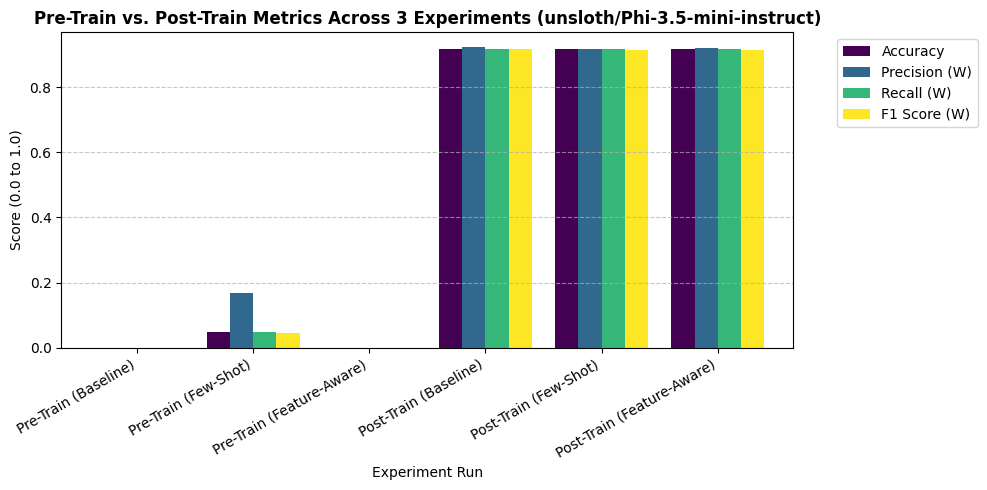

Saved performance chart to '/content/drive/MyDrive/NLP_Checkpoints/phi_3_5_mini_banking_adapter/phi_3_5_mini_banking_adapter_metrics_chart.png'.


In [12]:
import pandas as pd
from tabulate import tabulate
import matplotlib.pyplot as plt

comparison_rows = []
for key, m in master_results.items():
    comparison_rows.append({
        "Experiment Run": key,
        "Accuracy": round(m["Accuracy"], 4),
        "Precision (W)": round(m["Precision (Weighted)"], 4),
        "Recall (W)": round(m["Recall (Weighted)"], 4),
        "F1 Score (W)": round(m["F1 (Weighted)"], 4),
        "Macro F1": round(m["F1 (Macro)"], 4),
    })

df_master = pd.DataFrame(comparison_rows)

print("\n" + "="*95)
print(f"MASTER EVALUATION REPORT: {MODEL_NAME} on Banking77 (10k Train / 1k Val / 2k Test)")
print("="*95)
print(tabulate(df_master, headers="keys", tablefmt="fancy_grid", showindex=False))

# Calculate Improvement Deltas
df_master["State"] = df_master["Experiment Run"].apply(lambda x: "Pre" if "Pre" in x else "Post")
df_master["Strategy"] = df_master["Experiment Run"].apply(lambda x: x.split("(")[1].replace(")", "").strip())

print("\n" + "="*95)
print("EXPERIMENT PERFORMANCE DELTAS (POST-TRAIN VS. PRE-TRAIN)")
print("="*95)
for strat in ["Baseline", "Few-Shot", "Feature-Aware"]:
    pre_rows = df_master[(df_master["Strategy"] == strat) & (df_master["State"] == "Pre")]
    post_rows = df_master[(df_master["Strategy"] == strat) & (df_master["State"] == "Post")]

    if len(pre_rows) > 0 and len(post_rows) > 0:
        pre = pre_rows.iloc[0]
        post = post_rows.iloc[0]

        acc_delta = (post["Accuracy"] - pre["Accuracy"]) * 100
        f1_delta = (post["F1 Score (W)"] - pre["F1 Score (W)"]) * 100
        macro_delta = (post["Macro F1"] - pre["Macro F1"]) * 100

        print(f"• Experiment Track: {strat.upper()}")
        print(f"    - Accuracy:        {pre['Accuracy']:.4f} -> {post['Accuracy']:.4f} (Gain: {acc_delta:+.2f}%)")
        print(f"    - Weighted F1:     {pre['F1 Score (W)']:.4f} -> {post['F1 Score (W)']:.4f} (Gain: {f1_delta:+.2f}%)")
        print(f"    - Macro F1:        {pre['Macro F1']:.4f} -> {post['Macro F1']:.4f} (Gain: {macro_delta:+.2f}%)\n")

# Save to CSV
csv_filename = os.path.join(CHECKPOINT_DIR, f"phi_3_5_mini_banking_adapter_master_metrics_summary.csv")
df_master.to_csv(csv_filename, index=False)
print(f"Saved complete metrics summary to '{csv_filename}'.")

# Side-by-Side Visualization Bar Chart
try:
    fig, ax = plt.subplots(figsize=(10, 5))
    df_plot = df_master.set_index("Experiment Run")[["Accuracy", "Precision (W)", "Recall (W)", "F1 Score (W)"]]
    df_plot.plot(kind="bar", ax=ax, colormap="viridis", width=0.8)
    plt.title(f"Pre-Train vs. Post-Train Metrics Across 3 Experiments ({MODEL_NAME})", fontsize=12, fontweight="bold")
    plt.ylabel("Score (0.0 to 1.0)")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    chart_path = os.path.join(CHECKPOINT_DIR, f"phi_3_5_mini_banking_adapter_metrics_chart.png")
    plt.savefig(chart_path, dpi=300)
    plt.show()
    print(f"Saved performance chart to '{chart_path}'.")
except Exception as e:
    print(f"Plotting skipped: {e}")


## 13. Storing & Exporting Fine-Tuned Model Weights
Persists LoRA adapters and tokenizers to:
1. **Local disk:** `phi_3_5_mini_banking_adapter_final`
2. **Google Drive (Colab):** `/content/drive/MyDrive/NLP_Checkpoints/phi_3_5_mini_banking_adapter/final_adapter`
3. **Kaggle Output:** `/kaggle/working/`
4. **Hugging Face Hub:** Push to remote repository


In [13]:
# 1. Local Adapter Export
LOCAL_SAVE_PATH = "phi_3_5_mini_banking_adapter_final"
model.save_pretrained(LOCAL_SAVE_PATH)
tokenizer.save_pretrained(LOCAL_SAVE_PATH)
print(f"Saved LoRA adapter weights locally to: {LOCAL_SAVE_PATH}")

# 2. Google Drive Export Status
print(f"Current persistent checkpoint path: {FINAL_ADAPTER_DIR}")


Unsloth: Restored added_tokens_decoder metadata in phi_3_5_mini_banking_adapter_final/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in phi_3_5_mini_banking_adapter_final.


Saved LoRA adapter weights locally to: phi_3_5_mini_banking_adapter_final
Current persistent checkpoint path: /content/drive/MyDrive/NLP_Checkpoints/phi_3_5_mini_banking_adapter/final_adapter


## 14. Interactive Gradio Web Demonstration
Provides an interactive web application allowing users to input arbitrary customer banking queries, select one of the 3 prompting methods, and inspect predictions alongside extracted domain feature profiles.


In [14]:
# import gradio as gr

# FastLanguageModel.for_inference(model)

# def predict_banking_query(query_text, strategy):
#     if not query_text.strip():
#         return "Please input a customer banking query to analyze.", ""

#     strat_key = strategy.lower().replace("-", "_").replace(" ", "_")
#     prompt = create_prompt(query_text, strategy=strat_key)
#     messages = [{"role": "user", "content": prompt}]
#     inputs = tokenizer.apply_chat_template(
#         messages,
#         tokenize=True,
#         add_generation_prompt=True,
#         return_tensors="pt"
#     ).to("cuda")

#     with torch.no_grad():
#         outputs = model.generate(
#             input_ids=inputs,
#             max_new_tokens=15,
#             temperature=0.1,
#             do_sample=False
#         )

#     gen_text = tokenizer.decode(outputs[0][inputs.shape[1]:], skip_special_tokens=True).strip()
#     predicted_label = parse_prediction(gen_text, BANKING77_LABELS)

#     feat = extract_banking_features(query_text)
#     feature_card = (
#         f"Financial Entities Detected: {', '.join(feat['entities'])}\n"
#         f"Action / Problem Indicators: {', '.join(feat['actions'])}\n"
#         f"Query Length Profile: {feat['word_count']} words"
#     )
#     return predicted_label, feature_card

# demo = gr.Interface(
#     fn=predict_banking_query,
#     inputs=[
#         gr.Textbox(
#             lines=4,
#             placeholder="Enter customer service query here...",
#             label="Customer Banking Query",
#             value="I ordered a replacement card two weeks ago but it still hasn't arrived. How can I track the delivery?"
#         ),
#         gr.Radio(
#             choices=["Baseline", "Few-Shot", "Feature-Aware"],
#             value="Baseline",
#             label="Prompting Strategy"
#         )
#     ],
#     outputs=[
#         gr.Textbox(label="Predicted Banking Intent (Banking77 Taxonomy)", lines=2),
#         gr.Textbox(label="Domain Feature Profile", lines=4)
#     ],
#     title="Banking Customer Intent Classification Assistant",
#     description="Fine-tuned on Phi-3.5-mini-Instruct with Unsloth & QLoRA on the Banking77 benchmark across 77 fine-grained intent classes."
# )

# demo.launch(share=True, debug=False)
